In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import cmcrameri.cm as cmc

def parse_comsol_data(filepath):
    """
    Parse COMSOL data file and return organized DataFrame.
    
    Parameters:
    -----------
    filepath : str
        Path to the COMSOL data file
        
    Returns:
    --------
    pd.DataFrame
        DataFrame with columns for coordinates, physical parameters, U_in, and Sb_option
    """
    
    with open(filepath, 'r') as file:
        lines = file.readlines()
    
    # Find the header line with column names
    header_line = None
    data_start = None
    
    for i, line in enumerate(lines):
        if line.startswith('% r;z;'):
            header_line = line.strip()
            data_start = i + 1
            break
    
    if header_line is None:
        raise ValueError("Could not find header line starting with '% r;z;'")
    
    # Parse the header to extract column information
    header_line = header_line[2:]  # Remove '% ' prefix
    
    # Split the header and extract parameter names and conditions
    columns = header_line.split(';')
    
    # Parse column names to extract parameter names, U_in values, and Sb_option values
    parsed_columns = []
    
    for col in columns:
        if '@' in col:
            # Extract parameter name and conditions
            parts = col.split('@')
            param_name = parts[0].strip()
            conditions = parts[1].strip()
            
            # Extract U_in value
            u_in_match = re.search(r'U_in=([0-9E.-]+)', conditions)
            u_in = float(u_in_match.group(1)) if u_in_match else None
            
            # Extract Sb_option value
            sb_match = re.search(r'Sb_option=([0-9]+)', conditions)
            sb_option = int(sb_match.group(1)) if sb_match else None
            
            parsed_columns.append({
                'original_name': col,
                'param_name': param_name,
                'u_in': u_in,
                'sb_option': sb_option
            })
        else:
            # Coordinate columns (r, z)
            parsed_columns.append({
                'original_name': col,
                'param_name': col,
                'u_in': None,
                'sb_option': None
            })
    
    # Read the data
    data_lines = lines[data_start:]
    
    # Parse data rows
    data_rows = []
    for line in data_lines:
        if line.strip():  # Skip empty lines
            values = [float(x) for x in line.strip().split(';')]
            data_rows.append(values)
    
    # Create DataFrame with original column structure
    df_raw = pd.DataFrame(data_rows, columns=[col['original_name'] for col in parsed_columns])
    
    # Reorganize data by grouping parameters by U_in and Sb_option
    organized_data = []
    
    # Get coordinate columns (r, z)
    coord_cols = [col for col in parsed_columns if col['u_in'] is None]
    
    # Get unique combinations of U_in and Sb_option
    param_cols = [col for col in parsed_columns if col['u_in'] is not None]
    unique_conditions = set((col['u_in'], col['sb_option']) for col in param_cols)
    
    for u_in, sb_option in unique_conditions:
        # Get all parameter columns for this condition
        condition_cols = [col for col in param_cols 
                         if col['u_in'] == u_in and col['sb_option'] == sb_option]
        
        # For each row in the original data
        for idx, row in df_raw.iterrows():
            # Start with coordinates
            row_data = {'r': row[coord_cols[0]['original_name']], 
                       'z': row[coord_cols[1]['original_name']]}
            
            # Add condition identifiers
            row_data['U_in'] = u_in
            row_data['Sb_option'] = sb_option
            
            # Add all parameters for this condition
            for col in condition_cols:
                param_name = col['param_name']
                # Clean up parameter names (remove units and extra info)
                clean_param_name = param_name.split('(')[0].strip()
                row_data[clean_param_name] = row[col['original_name']]
            
            organized_data.append(row_data)
    
    # Create the final organized DataFrame
    df_organized = pd.DataFrame(organized_data)
    
    # Sort by U_in, Sb_option, and spatial coordinates
    df_organized = df_organized.sort_values(['U_in', 'Sb_option', 'r', 'z']).reset_index(drop=True)
    
    return df_organized
def calculate_excess_pressure(df):
    """
    Calculate excess pressure as linproj_r - rho_e*g*depth.
    
    Parameters:
    -----------
    df : pd.DataFrame
        The organized dataframe from parse_comsol_data
        
    Returns:
    --------
    pd.DataFrame
        DataFrame with added P_excess column
    """
    df_copy = df.copy()
    
    # Constants
    rho_e = 2700  # kg/m³
    g = 9.81      # m/s²
    
    # Calculate excess pressure
    # P_excess = linproj_r - rho_e * g * depth
    # Note: z is negative (z=0 at surface, z=-5000 at 5km depth)
    # So depth = -z (depth is positive)
    depth = -df_copy['z']  # Convert negative z to positive depth
    df_copy['P_excess'] = df_copy['linproj_r'] - (rho_e * g * depth +2.5e6+1e5)  # Adding 2.5 MPa offset for lithostatic pressure at surface
    
    print(f"Debug: z range: {df_copy['z'].min()} to {df_copy['z'].max()}")
    print(f"Debug: depth range: {depth.min()} to {depth.max()}")
    print(f"Debug: linproj_r range: {df_copy['linproj_r'].min()} to {df_copy['linproj_r'].max()}")
    print(f"Debug: P_excess range: {df_copy['P_excess'].min()} to {df_copy['P_excess'].max()}")
    
    return df_copy


In [3]:
def get_colormap(colormap):
    """
    Try to get a colormap from cmcrameri.cm, else fallback to matplotlib colormaps.
    """
    import matplotlib.pyplot as plt
    import cmcrameri.cm as cmc
    try:
        return getattr(cmc, colormap)
    except AttributeError:
        try:
            return plt.get_cmap(colormap)
        except Exception:
            print(f"Colormap '{colormap}' not found in cmcrameri or matplotlib. Using 'viridis'.")
            return plt.cm.viridis

In [4]:
df_slip_law = parse_comsol_data('../../data/4_slip_at_wall/conduit_wall_slip_colima_tau_ref_5e6MPA.txt')
# remove colum 'Sb_option'
df_slip_law = df_slip_law.drop(columns=['Sb_option'])
df_slip_law['Slip']= 'Friction Law'


In [5]:
df_slip_law

,r,z,U_in,Xc_nocap,Xc,Sb,Xg,spf.mu*spf.sr,rho_b,rho_m,...,T,linproj_r,mu_m,nu_b_inf,nu_c,mu_mbc,u_av,Cw,spf.U,Slip
0,15.0,-2895.466455,0.00001,0.400066,0.400066,0.0,0.0,0.403766,2700.0,2700.0,...,1223.0,7.919676e+07,3.296130e+04,1.0,4.593560,1.514097e+05,0.000010,0.030000,2.668384e-12,Friction Law
1,15.0,-2886.777268,0.00001,0.400077,0.400077,0.0,0.0,0.403794,2700.0,2700.0,...,1223.0,7.896661e+07,3.296130e+04,1.0,4.593871,1.514199e+05,0.000010,0.030000,2.666729e-12,Friction Law
2,15.0,-2879.160042,0.00001,0.400089,0.400089,0.0,0.0,0.403819,2700.0,2700.0,...,1223.0,7.876486e+07,3.296130e+04,1.0,4.594164,1.514296e+05,0.000010,0.030000,2.666769e-12,Friction Law
3,15.0,-2878.132411,0.00001,0.400090,0.400090,0.0,0.0,0.403824,2700.0,2700.0,...,1223.0,7.873764e+07,3.296130e+04,1.0,4.594205,1.514310e+05,0.000010,0.030000,2.723147e-12,Friction Law
4,15.0,-2876.585622,0.00001,0.400093,0.400093,0.0,0.0,0.403827,2700.0,2700.0,...,1223.0,7.869667e+07,3.296130e+04,1.0,4.594268,1.514330e+05,0.000010,0.030000,2.666746e-12,Friction Law
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
286921,15.0,-3.482659,1.00000,0.400001,0.400001,0.0,0.0,317.209747,2700.0,2700.0,...,1223.0,2.590635e+06,1.227202e+07,1.0,4.591862,5.635141e+07,0.972960,0.002590,9.729571e-01,Friction Law
286922,15.0,-2.432795,1.00000,0.400001,0.400001,0.0,0.0,307.902064,2700.0,2700.0,...,1223.0,2.562871e+06,1.230136e+07,1.0,4.591862,5.648616e+07,0.972955,0.002585,9.729530e-01,Friction Law
286923,15.0,-2.083809,1.00000,0.400001,0.400001,0.0,0.0,304.829473,2700.0,2700.0,...,1223.0,2.553641e+06,1.231093e+07,1.0,4.591862,5.653008e+07,0.972954,0.002584,9.729517e-01,Friction Law
286924,15.0,-1.387282,1.00000,0.400001,0.400001,0.0,0.0,298.726393,2700.0,2700.0,...,1223.0,2.535221e+06,1.232973e+07,1.0,4.591862,5.661644e+07,0.972952,0.002581,9.729491e-01,Friction Law


In [6]:
df_no_slip = parse_comsol_data('../../data/4_slip_at_wall/conduit_wall_no_slip_colima.txt')
df_no_slip['Slip']= 'No Slip'
df_no_slip = df_no_slip.drop(columns=['Sb_option'])

# df_slip = parse_comsol_data('conduit_wall_slip.txt')
# df_slip['Slip']= 'Slip at z=-500 m'
# df_slip = df_slip.drop(columns=['Sb_option'])

In [7]:
df = pd.concat([df_no_slip, df_slip_law], ignore_index=True)
# remove any rows with NaN values
df = df.dropna()



velocities = sorted(df['U_in'].unique())
n_velocities = len(velocities)

variables = {
        'w': ' Velocity at \nwall (m/s)',
        'P_excess': 'Excess Pressure\n (MPa)',
        'spf.mu*spf.sr': 'Shear Stress\n (MPa)',
    }


In [8]:
df

,r,z,U_in,Xc_nocap,Xc,Sb,Xg,spf.mu*spf.sr,rho_b,rho_m,...,T,linproj_r,mu_m,nu_b_inf,nu_c,mu_mbc,u_av,Cw,spf.U,Slip
0,15.0,-2895.466455,0.00001,0.400066,0.400066,0.0,0.0,0.403766,2700.0,2700.0,...,1223.0,7.919676e+07,3.296130e+04,1.0,4.593560,1.514097e+05,0.000010,0.030000,0.000000,No Slip
1,15.0,-2886.777268,0.00001,0.400077,0.400077,0.0,0.0,0.403794,2700.0,2700.0,...,1223.0,7.896661e+07,3.296130e+04,1.0,4.593871,1.514199e+05,0.000010,0.030000,0.000000,No Slip
2,15.0,-2879.160042,0.00001,0.400089,0.400089,0.0,0.0,0.403819,2700.0,2700.0,...,1223.0,7.876486e+07,3.296130e+04,1.0,4.594164,1.514296e+05,0.000010,0.030000,0.000000,No Slip
3,15.0,-2878.132411,0.00001,0.400090,0.400090,0.0,0.0,0.403823,2700.0,2700.0,...,1223.0,7.873764e+07,3.296130e+04,1.0,4.594205,1.514310e+05,0.000010,0.030000,0.000000,No Slip
4,15.0,-2876.585622,0.00001,0.400093,0.400093,0.0,0.0,0.403827,2700.0,2700.0,...,1223.0,7.869667e+07,3.296130e+04,1.0,4.594268,1.514330e+05,0.000010,0.030000,0.000000,No Slip
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
573847,15.0,-3.482659,1.00000,0.400001,0.400001,0.0,0.0,317.209747,2700.0,2700.0,...,1223.0,2.590635e+06,1.227202e+07,1.0,4.591862,5.635141e+07,0.972960,0.002590,0.972957,Friction Law
573848,15.0,-2.432795,1.00000,0.400001,0.400001,0.0,0.0,307.902064,2700.0,2700.0,...,1223.0,2.562871e+06,1.230136e+07,1.0,4.591862,5.648616e+07,0.972955,0.002585,0.972953,Friction Law
573849,15.0,-2.083809,1.00000,0.400001,0.400001,0.0,0.0,304.829473,2700.0,2700.0,...,1223.0,2.553641e+06,1.231093e+07,1.0,4.591862,5.653008e+07,0.972954,0.002584,0.972952,Friction Law
573850,15.0,-1.387282,1.00000,0.400001,0.400001,0.0,0.0,298.726393,2700.0,2700.0,...,1223.0,2.535221e+06,1.232973e+07,1.0,4.591862,5.661644e+07,0.972952,0.002581,0.972949,Friction Law


Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2198529.6662007687 to 120049243.82404754
Debug: P_excess range: -433611.027068052 to 37988243.824047536
Slip_option No Slip, U_in 1e-05: z=-3000.0, linproj_r=8.20e+07, P_excess=-9.55e+04
Slip_option No Slip, U_in 1.2589e-05: z=-3000.0, linproj_r=8.20e+07, P_excess=-9.48e+04
Slip_option No Slip, U_in 1.5849e-05: z=-3000.0, linproj_r=8.20e+07, P_excess=-9.39e+04
Slip_option Friction Law, U_in 1e-05: z=-3000.0, linproj_r=8.20e+07, P_excess=-9.55e+04
Slip_option Friction Law, U_in 1.2589e-05: z=-3000.0, linproj_r=8.20e+07, P_excess=-9.48e+04
Slip_option Friction Law, U_in 1.5849e-05: z=-3000.0, linproj_r=8.20e+07, P_excess=-9.39e+04


(-2.0, 40.0)

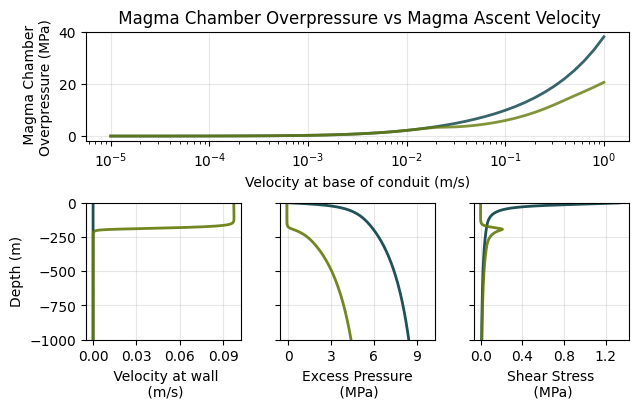

In [9]:
# Create subplots: main grid + bottom row for P_excess vs U_in
from matplotlib.ticker import MaxNLocator


variables = {
        'spf.U': ' Velocity at wall\n (m/s)',
        'P_excess': 'Excess Pressure\n (MPa)',
        'spf.mu*spf.sr': 'Shear Stress\n (MPa)',
    }

try:
    oslo_cmap = cmc.bamako
except AttributeError:
    oslo_cmap = plt.cm.Blues

slip_options = df['Slip'].unique()
df = calculate_excess_pressure(df)
n_slip_options = len(slip_options)
n_vars = len(variables)
slip_colors = [oslo_cmap(0.05), oslo_cmap(0.5), oslo_cmap(0.7)]
slip_to_color = {slip_option: slip_colors[i % 3] for i, slip_option in enumerate(slip_options)}
#slip_labels = {'Friction Law Slip': '100% Gas Loss', 4: 'Step Gas Loss at Xg = 0.3', 6: 'Sustained Gas Loss at Xg = 0.3'}
#slip_to_label = {slip_option: slip_labels.get(slip_option, f'Slip = {slip_option}') for slip_option in slip_options}
    
figsize=(7, 4)
fig = plt.figure(figsize=figsize)
gs = fig.add_gridspec(2, 3, height_ratios=[0.8] + [1]*1,#n_sb_options, 
                          width_ratios=[1]*3, #[1, 1, 1, 0.3, 1, 1, 1],
                          hspace=0.5, wspace=0.25)


main_axes = []
    # Top row (span all columns)
top_ax = fig.add_subplot(gs[0, :])

    # Bottom row: 3 left, 1 gap, 3 right
bottom_axes = []

for i in range(3):
    ax = fig.add_subplot(gs[1, i])
    bottom_axes.append(ax)

main_axes.append(top_ax)
main_axes.append(bottom_axes)

selected_velocities = [0.1]

for i, slip in enumerate(slip_options):
    df_filtered = df[df['Slip'] == slip].copy()
    for n, velocity in enumerate(selected_velocities):
        constant_row = n * n_vars
        for j, (var, var_name) in enumerate(variables.items()):
            ax = main_axes[1][constant_row + j]
            #import pdb;pdb.set_trace()
            # Special handling for 1-Sb - plot in same colors as bottom row
           
                # Plot other variables with colormap
        
            data_subset = df_filtered[df_filtered['U_in'] == velocity]
            
            if not data_subset.empty and var in data_subset.columns:
                # Sort by depth for proper line plotting
                data_subset = data_subset.sort_values('z')
                depth = data_subset['z']
                
                # Get color based on velocity using log scale
                #color_index = velocity_to_color[velocity]  # Now already normalized 0-1
                color = slip_to_color[slip]
                if var in ['spf.mu*spf.sr', 'P_excess']:
                    plot_vals = data_subset[var] / 1e6
                    x_label = var_name.replace('(Pa)', '(MPa)')
            
                else:
                    plot_vals = data_subset[var]
                    x_label = var_name
                ax.plot(plot_vals, depth, color=color, linewidth=2, alpha=0.9)
                            
    
                    # Set logarithmic scale for shear stress and magma viscosity only
            # if var in [ 'spf.mu*spf.sr']:
            #     ax.set_xscale('log')
            if ax.get_xscale() == 'log':
                pass
            else:
                ax.xaxis.set_major_locator(MaxNLocator(nbins=4, prune=None))
            
      
            ax.set_ylim([-1000,0])
            ax.set_xlabel(var_name)
            ax.tick_params(axis='x', labelbottom=True)
            if j == 0:  # Left column
                ax.set_ylabel(f"Depth (m)")#\n{sb_labels.get(sb_option, f'{sb_option}')}")
            else:
                ax.set_ylabel("")
                # Hide y-tick labels for non-leftmost plots
                ax.set_yticklabels([])
            
            ax.grid(True, alpha=0.3)
                

sb_markers = ['o', 's', '^']  # Different markers for each Sb_option
legend_handles = []
for idx, slip_option in enumerate(slip_options):
    df_slip = df[df['Slip'] == slip_option].copy()
    p_excess_deepest = []
    velocities_plot = []
    colors_plot = []
    for velocity in velocities:
        df_vel = df_slip[df_slip['U_in'] == velocity]
        if not df_vel.empty:
            deepest_idx = df_vel['z'].idxmin()
            deepest_z = df_vel.loc[deepest_idx, 'z']
            deepest_p_excess = df_vel.loc[deepest_idx, 'P_excess']
            deepest_linproj = df_vel.loc[deepest_idx, 'linproj_r']
            p_excess_deepest.append(deepest_p_excess)
            # list to np array 
            
            velocities_plot.append(velocity)
            if len(velocities_plot) <= 3:
                print(f"Slip_option {slip_option}, U_in {velocity}: z={deepest_z:.1f}, linproj_r={deepest_linproj:.2e}, P_excess={deepest_p_excess:.2e}")
            # Get colour based on slip option 
            color = slip_to_color[slip_option]
            

    p_excess_deepest = np.array(p_excess_deepest)/1e6
    # Plot each point with its color
    top_ax.semilogx(velocities_plot, p_excess_deepest, color=slip_to_color[slip_option], alpha=0.8, linewidth=2)
    for v, p, c in zip(velocities_plot, p_excess_deepest, colors_plot):
        print(c)
        top_ax.semilogx(v, p, marker='o', color=slip_to_color[slip_option], markersize=4, linewidth=0)       
    
    
    
    # top_ax.semilogx(velocities_plot, p_excess_deepest, 
    #         color=sb_to_color[sb_option],
    #         marker=sb_markers[idx % len(sb_markers)],
    #         markersize=8, linewidth=2, alpha=0.8,
    #         label=sb_to_label[sb_option])
    legend_handles.append(
        plt.Line2D([], [], color=slip_to_color[slip_option], marker=sb_markers[idx % len(sb_markers)], linestyle='-', markersize=10, label=slip_option)
    )

top_ax.set_xlabel('Velocity at base of conduit (m/s)')
top_ax.set_ylabel(' Magma Chamber\nOverpressure (MPa)')
top_ax.set_title(' Magma Chamber Overpressure vs Magma Ascent Velocity')
top_ax.grid(True, alpha=0.3)
# v line at 0.1 m/s and 0.001 m/s
# top_ax.axvline(0.1, color='red', linestyle='--', linewidth=1, alpha=0.7)
# top_ax.axvline(0.001, color='blue', linestyle='--', linewidth=1, alpha=0.7)
# # set hline at 0 Mpa and 5 MPa
# top_ax.axhline(2, color='black', linestyle='--', linewidth=1, alpha=0.7)
# top_ax.axhline(5, color='black', linestyle='--', linewidth=1, alpha=0.7)
top_ax.set_ylim(-2, 40)
#top_ax.legend(handles=legend_handles, title='Outgassing Model', fontsize=7, title_fontsize=8, loc='center left', bbox_to_anchor=(1, 0.5))
#top_ax.set_xlim([2e-2,1.2])

In [10]:

def parse_comsol_edge_data(filepath,var_names):
    with open(filepath, 'r') as file:
        lines = file.readlines()

    # Find the header line with column names
    header_line = None
    data_start = None

    for i, line in enumerate(lines):
        if line.startswith('% r;z;'):
            header_line = line.strip()
            data_start = i + 1
            break

    if header_line is None:
        raise ValueError("Could not find header line starting with '% r;z;'")

    # Parse the header to extract column information
    header_line = header_line[2:]  # Remove '% ' prefix

    #print(f"Header line: {header_line}")
    # Split the header and extract parameter names and conditions
    columns = header_line.split(';')

    # Parse column names to extract parameter names, U_in values, and Sb_option values
    parsed_columns = {}

    df = pd.DataFrame(index=range(len(columns)),columns=['param_name']+var_names)

    for i, col in enumerate(columns):
        #print('col:' + col)
        if '@' in col:
            # Extract parameter name and conditions
            parts = col.split('@')
            param_name = parts[0].strip()
            conditions = parts[1].strip()
            vars=conditions.split(',')

            
            
            df.at[i, 'param_name'] = param_name


            for k,var in enumerate(vars):
                if '=' in var:
                    key, value = var.split('=')
                    key = key.strip()
                    value = value.strip()
                    #print(f"Condition: {key} = {float(value)}")
                    df.at[i, var_names[k]] = float(value)
                else:
                    #print(f"Condition: {var_names[k]} : {var}")
                    df.at[i, var_names[k]] = var
        else:
            # Coordinate columns (r, z)
            df.at[i, 'param_name'] = col.strip()
            for k,var in enumerate(var_names):
                df.at[i, var_names[k]] = None
            
        
    data_lines = lines[data_start:]
    # # Parse data rows
    data_rows = []
    for line in data_lines:
        if line.strip():  # Skip empty lines
            values = [float(x) for x in line.strip().split(';')]
            data_rows.append(values)

    # # Create DataFrame with original column structure
    df_raw = pd.DataFrame(data_rows, columns=['r','z']+columns[2:])

    # Create new dataframe that will be the final export
    # params = df['param_name'].dropna().unique()
    #print(params.tolist()+var_names)

    # # Read the data

    params = df['param_name'].dropna().unique()

    params_list = params
    params_list = params_list[2:]
    print(params.tolist()+var_names)
    columns = params.tolist()+var_names

    # find unique values of each parameter
    df_vars = df.drop('param_name',axis=1)
    df_unique_vars= df_vars.drop_duplicates(keep='first').dropna(how='all')

    print('Number of rows in new dataframe')
    n_rows = df_raw.shape[0]*np.shape(df_unique_vars)[0]
    print(n_rows)

    output_df = pd.DataFrame(index=range(n_rows),columns=columns)
    print('Number of unique variables:' ,np.shape(df_unique_vars))


    param = params_list[0]
    for param in params_list:
        row_idx = 0
        for idx, row in df_unique_vars.iterrows():
            
            
                print('loop start')
                #print(f"Processing param: {param}")
                print(f"Processing param: {param}")
                row['param_name'] = param

                # find which rows in df match this row 
                mask = (df[row.index] == row.values).all(axis=1)
                matching_rows = df[mask]
                for raw_idx, raw_row in df_raw.iterrows():
                    value=raw_row.iloc[matching_rows.index.to_list()[0]]
                    
                    r = raw_row['r']
                    z = raw_row['z']

                    output_df.at[row_idx, 'r'] = r
                    output_df.at[row_idx, 'z'] = z
                    
                    for var_name in var_names:
                        print(row_idx,var_name)
                        output_df.at[row_idx, var_name] = row[var_name]  
                    output_df.at[row_idx, param] = value 
                    row_idx += 1

    new_names = []
    for i,name in enumerate(output_df.columns):
        
        new_names.append(name.split(' ')[0])

    output_df.columns = new_names

    return output_df






In [11]:

filepath = '../../data/4_slip_at_wall/ground_edge_slip_colima_tau_ref_5e6MPA.txt'

var_names = ['U_in', 'beta_b', 'tau_ref', 'n_Wi', 'param_def']
df_ge_nonnav = parse_comsol_edge_data(filepath,var_names)

# filepath = '../../data/4_slip_at_wall/ground_edge_slip_500m.txt'

# var_names = ['U_in', 'C_R', 'Colima', 'h2oc', 'T', 'nu_c_max', 'Sb_option', 'param_def']
# df_ge_slip_500m = parse_comsol_edge_data(filepath,var_names)

filepath = '../../data/4_slip_at_wall/ground_edge_no_slip_colima.txt'

var_names = ['U_in', 'param_def']
df_ge_noslip = parse_comsol_edge_data(filepath,var_names)

# df_ge_slip_500m['Slip']= 'Slip at z=-500 m'
# df_ge_slip_500m = df_ge_slip_500m.drop(columns=['Sb_option'])

df_ge_nonnav['Slip']= 'Friction Law'
#df_ge_nonnav = df_ge_nonnav.drop(columns=['Sb_option'])

df_ge_noslip['Slip']= 'No Slip'
#df_ge_noslip = df_ge_noslip.drop(columns=['Sb_option'])

# df_ge = pd.concat([df_ge_noslip, df_ge_nonnav,df_ge_slip_500m], ignore_index=True)
df_ge = pd.concat([df_ge_noslip, df_ge_nonnav], ignore_index=True)




['r', 'z', 'u2 (m)', 'v2 (m)', 'w2 (m)', 'solid.RotrZ (rad)', 'U_in', 'beta_b', 'tau_ref', 'n_Wi', 'param_def']
Number of rows in new dataframe
13464
Number of unique variables: (153, 5)
loop start
Processing param: u2 (m)
0 U_in
0 beta_b
0 tau_ref
0 n_Wi
0 param_def
1 U_in
1 beta_b
1 tau_ref
1 n_Wi
1 param_def
2 U_in
2 beta_b
2 tau_ref
2 n_Wi
2 param_def
3 U_in
3 beta_b
3 tau_ref
3 n_Wi
3 param_def
4 U_in
4 beta_b
4 tau_ref
4 n_Wi
4 param_def
5 U_in
5 beta_b
5 tau_ref
5 n_Wi
5 param_def
6 U_in
6 beta_b
6 tau_ref
6 n_Wi
6 param_def
7 U_in
7 beta_b
7 tau_ref
7 n_Wi
7 param_def
8 U_in
8 beta_b
8 tau_ref
8 n_Wi
8 param_def
9 U_in
9 beta_b
9 tau_ref
9 n_Wi
9 param_def
10 U_in
10 beta_b
10 tau_ref
10 n_Wi
10 param_def
11 U_in
11 beta_b
11 tau_ref
11 n_Wi
11 param_def
12 U_in
12 beta_b
12 tau_ref
12 n_Wi
12 param_def
13 U_in
13 beta_b
13 tau_ref
13 n_Wi
13 param_def
14 U_in
14 beta_b
14 tau_ref
14 n_Wi
14 param_def
15 U_in
15 beta_b
15 tau_ref
15 n_Wi
15 param_def
16 U_in
16 beta_b
16 tau_re

In [12]:
velocities[::5]

[1e-05,
 3.1623e-05,
 0.0001,
 0.00031623,
 0.001,
 0.0031623,
 0.01,
 0.031623,
 0.1,
 0.31623,
 1.0]

Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2198529.6662007687 to 120049243.82404754
Debug: P_excess range: -433611.027068052 to 37988243.824047536
Slip_option Friction Law, U_in 0.001: z=-3000.0, linproj_r=8.22e+07, P_excess=1.82e+05
Slip_option Friction Law, U_in 0.0012589: z=-3000.0, linproj_r=8.23e+07, P_excess=2.52e+05
Slip_option Friction Law, U_in 0.0015849: z=-3000.0, linproj_r=8.24e+07, P_excess=3.37e+05
Plotting tilt data
[0.0 1.0 2.0]


/var/folders/mx/bkycrpt14j74yd4cg6dr43sh0000gn/T/ipykernel_89664/1913710773.py:309: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.85, 1])


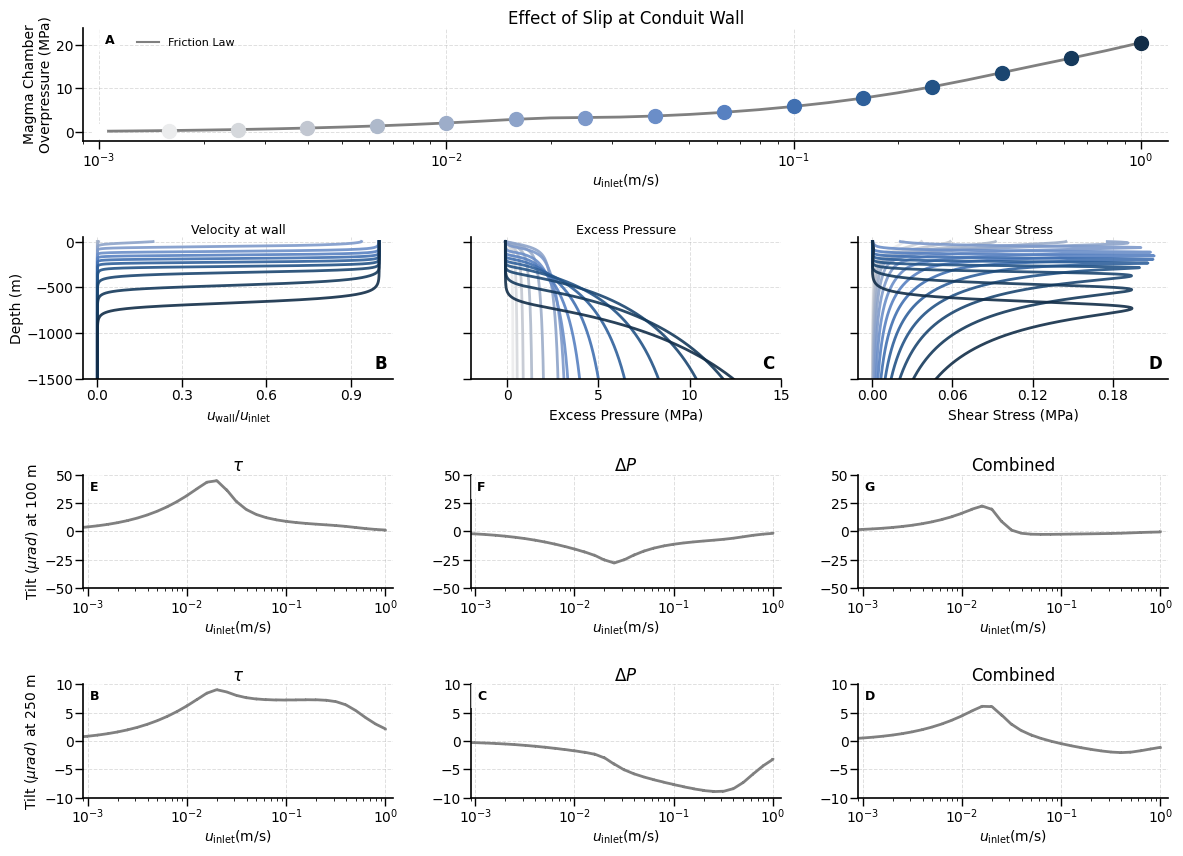

In [13]:
# Create subplots: main grid + bottom row for P_excess vs U_in
from matplotlib.ticker import MaxNLocator, LogLocator
import matplotlib as mpl
from shapely import transform
mpl.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 10,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 12
})

variables = {
        'spf.U': ' Velocity at wall (m/s)',
        'P_excess': 'Excess Pressure (MPa)',
        'spf.mu*spf.sr': 'Shear Stress (MPa)',
    }

try:
    oslo_cmap = cmc.bamako
except AttributeError:
    oslo_cmap = plt.cm.Blues

slip_options = ['Friction Law']#df['Slip'].unique()
df = calculate_excess_pressure(df)
n_slip_options = len(slip_options)
n_vars = len(variables)
slip_colors = ['grey']#oslo_cmap(0.05), oslo_cmap(0.5), oslo_cmap(0.7)]
slip_to_color = {slip_option: slip_colors[i % 3] for i, slip_option in enumerate(slip_options)}
#slip_labels = {'Non-Navier Slip': '100% Gas Loss', 4: 'Step Gas Loss at Xg = 0.3', 6: 'Sustained Gas Loss at Xg = 0.3'}
#slip_to_label = {slip_option: slip_labels.get(slip_option, f'Slip = {slip_option}') for slip_option in slip_options}
 
figsize=(7*2, 5*2)
fig = plt.figure(figsize=figsize)
gs = fig.add_gridspec(4, 3, height_ratios=[0.8] + [1]*1+[0.8]+[0.8],#n_sb_options, 
                          width_ratios=[1]*3, #[1, 1, 1, 0.3, 1, 1, 1],
                          hspace=0.8, wspace=0.25)


main_axes = []
    # Top row (span all columns)
top_ax = fig.add_subplot(gs[0, :])
top_ax2_0 = fig.add_subplot(gs[3, 0], sharex=top_ax)
top_ax3_0 = fig.add_subplot(gs[2, 0], sharex=top_ax)
top_ax2_1 = fig.add_subplot(gs[3, 1], sharex=top_ax)
top_ax3_1 = fig.add_subplot(gs[2, 1], sharex=top_ax)
top_ax2_2 = fig.add_subplot(gs[3, 2], sharex=top_ax)
top_ax3_2 = fig.add_subplot(gs[2, 2], sharex=top_ax)
top_ax3 = [top_ax3_0, top_ax3_1, top_ax3_2]
top_ax2 = [top_ax2_0, top_ax2_1, top_ax2_2]
    # Bottom row: 3 left, 1 gap, 3 right
bottom_axes = []

for i in range(3):
    ax = fig.add_subplot(gs[1, i])
    bottom_axes.append(ax)

main_axes.append(top_ax)
main_axes.append(bottom_axes)

velocities = np.array(velocities)

velocities = velocities[velocities >= 1e-3]
selected_velocities = velocities[::2]

n = len(selected_velocities)
# RGBA colours
vel_colours = [cmc.oslo(x) for x in np.linspace(1, 0.2, n)]



for i, slip in enumerate(slip_options):
    df_filtered = df[df['Slip'] == slip].copy()
    for n, velocity in enumerate(selected_velocities):
        constant_row = 1 * n_vars
        for j, (var, var_name) in enumerate(variables.items()):
            ax = main_axes[1][j]
            #import pdb;pdb.set_trace()
            # Special handling for 1-Sb - plot in same colors as bottom row
           
                # Plot other variables with colormap
        
            data_subset = df_filtered[df_filtered['U_in'] == velocity]
            
            if not data_subset.empty and var in data_subset.columns:
                # Sort by depth for proper line plotting
                data_subset = data_subset.sort_values('z')
                depth = data_subset['z']
                
                # Get color based on velocity using log scale
                #color_index = velocity_to_color[velocity]  # Now already normalized 0-1
                color = slip_to_color[slip]
                if var in ['spf.mu*spf.sr', 'P_excess']:
                    plot_vals = data_subset[var] / 1e6
                    x_label = var_name.replace('(Pa)', '(MPa)')

                elif var == 'spf.U':
                    plot_vals = data_subset[var]/data_subset['u_av']
                    x_label = '$u_\mathrm{wall}/u_\mathrm{inlet}$'
                    
                else:
                    plot_vals = data_subset[var]
                    x_label = var_name
                    
                ax.plot(plot_vals, depth, color=vel_colours[n], linewidth=2, alpha=0.9)
                            
    
                    # Set logarithmic scale for shear stress and magma viscosity only
            # if var in [ 'spf.mu*spf.sr']:
            #     ax.set_xscale('log')
            if ax.get_xscale() == 'log':
                pass
            else:
                ax.xaxis.set_major_locator(MaxNLocator(nbins=4, prune=None))
            
            ax.set_ylim([-1500,50])
            if var == 'P_excess':
                ax.set_xlim([-2, 15])
            ax.set_xlabel(x_label)
            ax.tick_params(axis='x', labelbottom=True)
            if j == 0:  # Left column
                ax.set_ylabel(f"Depth (m)",labelpad=2)#\n{sb_labels.get(sb_option, f'{sb_option}')}")
            else:
                ax.set_ylabel("")
                # Hide y-tick labels for non-leftmost plots
                ax.set_yticklabels([])
            
            ax.grid(True, alpha=0.3)
                

sb_markers = ['o', 's', '^']  # Different markers for each Sb_option
legend_handles = []
for idx, slip_option in enumerate(slip_options):
    df_slip = df[df['Slip'] == slip_option].copy()
    p_excess_deepest = []
    velocities_plot = []
    colors_plot = []
    
    for velocity in velocities:
        df_vel = df_slip[df_slip['U_in'] == velocity]
        if not df_vel.empty:
            deepest_idx = df_vel['z'].idxmin()
            deepest_z = df_vel.loc[deepest_idx, 'z']
            deepest_p_excess = df_vel.loc[deepest_idx, 'P_excess']
            deepest_linproj = df_vel.loc[deepest_idx, 'linproj_r']
            p_excess_deepest.append(deepest_p_excess)
            # list to np array 
            
            velocities_plot.append(velocity)
            if len(velocities_plot) <= 3:
                print(f"Slip_option {slip_option}, U_in {velocity}: z={deepest_z:.1f}, linproj_r={deepest_linproj:.2e}, P_excess={deepest_p_excess:.2e}")
            # Get colour based on slip option 
            color = slip_to_color[slip_option]
            
    df_filtered = df_slip[df_slip['U_in'] >= 1e-3]

    # Find the deepest z for each velocity
    deepest_idx = df_filtered.groupby('U_in')['z'].idxmin()

    # Rows corresponding to deepest z
    df_deepest = df_filtered.loc[deepest_idx].sort_values('U_in')

    # Extract values
    velocities_deepest = df_deepest['U_in'].to_numpy()
    p_excess_deep = df_deepest['P_excess'].to_numpy()
    p_excess_deep = np.array(p_excess_deep)/1e6
    # Plot each point with its color
    top_ax.semilogx(velocities_deepest, p_excess_deep, color=slip_to_color[slip_option], alpha=1, linewidth=2)
    for i, (v, p) in enumerate(zip(velocities_plot[::2], p_excess_deepest[::2])):
        p = p / 1e6  # Convert to MPa
        top_ax.semilogx(v, p, marker='o', markersize=10, color=vel_colours[i], linewidth=0)       
    print('Plotting tilt data')
    print(df_ge['param_def'].unique())
    

    #linestyle = ['--','-',':']
    labels = ['Shear Stress Only','Shear Stress + Pressure','Pressure Only']
    for param_def in df_ge['param_def'].unique():

        if param_def == 0:
            #linestyle = 'dotted'
            df_param = df_ge[(df_ge['Slip']==slip_option)&(df_ge['param_def']==param_def)]
            top_ax2[0].semilogx(df_ge[(df_ge['Slip']==slip_option)&(df_ge['r']==250)&(df_ge['param_def']==param_def)]['U_in'],df_ge[(df_ge['Slip']==slip_option)&(df_ge['r']==250)&(df_ge['param_def']==param_def)]['solid.RotrZ']*1e6 , color=slip_to_color[slip_option], linestyle='-', alpha=1, linewidth=2)
            top_ax3[0].semilogx(df_ge[(df_ge['Slip']==slip_option)&(df_ge['r']==100)&(df_ge['param_def']==param_def)]['U_in'],df_ge[(df_ge['Slip']==slip_option)&(df_ge['r']==100)&(df_ge['param_def']==param_def)]['solid.RotrZ']*1e6 , color=slip_to_color[slip_option], linestyle='-', alpha=1, linewidth=2)
                                  
        elif param_def ==2:                        
            #linestyle = 'dashed'   
            df_param = df_ge[(df_ge['Slip']==slip_option)&(df_ge['param_def']==param_def)]
            top_ax2[1].semilogx(df_ge[(df_ge['Slip']==slip_option)&(df_ge['r']==250)&(df_ge['param_def']==param_def)]['U_in'],df_ge[(df_ge['Slip']==slip_option)&(df_ge['r']==250)&(df_ge['param_def']==param_def)]['solid.RotrZ']*1e6 , color=slip_to_color[slip_option], linestyle='-', alpha=1, linewidth=2)
            top_ax3[1].semilogx(df_ge[(df_ge['Slip']==slip_option)&(df_ge['r']==100)&(df_ge['param_def']==param_def)]['U_in'],df_ge[(df_ge['Slip']==slip_option)&(df_ge['r']==100)&(df_ge['param_def']==param_def)]['solid.RotrZ']*1e6 , color=slip_to_color[slip_option], linestyle='-', alpha=1, linewidth=2)
        elif param_def ==1:
            #linestyle = 'solid'   
            df_param = df_ge[(df_ge['Slip']==slip_option)&(df_ge['param_def']==param_def)]
            top_ax2[2].semilogx(df_ge[(df_ge['Slip']==slip_option)&(df_ge['r']==250)&(df_ge['param_def']==param_def)]['U_in'],df_ge[(df_ge['Slip']==slip_option)&(df_ge['r']==250)&(df_ge['param_def']==param_def)]['solid.RotrZ']*1e6 , color=slip_to_color[slip_option], linestyle='-', alpha=1, linewidth=2)
            top_ax3[2].semilogx(df_ge[(df_ge['Slip']==slip_option)&(df_ge['r']==100)&(df_ge['param_def']==param_def)]['U_in'],df_ge[(df_ge['Slip']==slip_option)&(df_ge['r']==100)&(df_ge['param_def']==param_def)]['solid.RotrZ']*1e6 , color=slip_to_color[slip_option], linestyle='-', alpha=1, linewidth=2)
        
            
    

    legend_handles.append(
        plt.Line2D([], [], color=slip_to_color[slip_option], linestyle='-', markersize=10, label=slip_option)
    )

top_ax.set_xlabel('$u_\mathrm{inlet}$(m/s)',  labelpad=2)
for ax in top_ax2:
    ax.set_xlabel('$u_\mathrm{inlet}$(m/s)',  labelpad=2)
for ax in top_ax3:
    ax.set_xlabel('$u_\mathrm{inlet}$(m/s)',  labelpad=2)

top_ax.set_ylabel('Magma Chamber\nOverpressure (MPa)', labelpad=2)
top_ax.set_title('Effect of Slip at Conduit Wall', pad=2)

#for ax in top_ax2:
top_ax2[0].set_ylabel('Tilt ($\mu rad$) at 250 m', labelpad=2)

top_ax3[0].set_ylabel('Tilt ($\mu rad$) at 100 m', labelpad=2)

top_ax2[0].set_title(r'$\tau$', pad=2)

top_ax3[0].set_title(r'$\tau$', pad=2)

top_ax2[1].set_title(r'$\Delta P$', pad=2)

top_ax3[1].set_title(r'$\Delta P$', pad=2)

top_ax2[2].set_title('Combined', pad=2)

top_ax3[2].set_title('Combined', pad=2)

# Set tick parameters for clarity

top_ax.tick_params(axis='both', which='major', direction='out', length=6, width=1,pad =1 )
for ax in top_ax2:
    ax.tick_params(axis='both', which='major', direction='out', length=6, width=1,pad =1 )
for ax in top_ax3:
    ax.tick_params(axis='both', which='major', direction='out', length=6, width=1,pad =1 )


# repeat for ax in bttom axes
for ax in bottom_axes:
    ax.tick_params(axis='both', which='major', direction='out', length=6, width=1,pad =1 )

# Add grid with better style
top_ax.grid(True, alpha=0.4, linestyle='--', linewidth=0.7)
for ax in top_ax2:
    ax.grid(True, alpha=0.4, linestyle='--', linewidth=0.7)
for ax in top_ax3:
    ax.grid(True, alpha=0.4, linestyle='--', linewidth=0.7)
for ax in bottom_axes:
    ax.grid(True, alpha=0.4, linestyle='--', linewidth=0.7)

# Set axis limits for clarity
top_ax.set_ylim(-2, 24)
top_ax.set_xlim([9e-4, 1.2])

for ax in top_ax2:
    ax.set_ylim([-10, 10])  
for ax in top_ax3:
    ax.set_ylim([-50, 50])  


# top_ax.axvline(0.1, color='blue', linestyle='--', linewidth=1, alpha=0.7)

# Add legend outside the plot for clarity
top_ax.legend(handles=legend_handles, fontsize=8, title_fontsize=9, loc='upper left', bbox_to_anchor=(0.04, 1), frameon=False)  # No box, clear background

# make spine of plot blue for ax in bottom row
for ax in bottom_axes:

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.2)
    ax.spines['bottom'].set_linewidth(1.2)

bottom_axes[0].set_title('Velocity at wall', fontsize=9, pad=2)
bottom_axes[1].set_title('Excess Pressure', fontsize=9, pad=2)
bottom_axes[2].set_title('Shear Stress', fontsize=9, pad=2)
# Add annotation for publication
top_ax.text(0.02, 0.95, 'A', transform=top_ax.transAxes, fontsize=9, fontweight='bold', va='top', ha='left', bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))
for i, ax in enumerate(top_ax2):
    ax.text(0.02, 0.95, chr(66 + i), transform=ax.transAxes, fontsize=9, fontweight='bold', va='top', ha='left', bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))
for i, ax in enumerate(top_ax3):
    ax.text(0.02, 0.95, chr(69 + i  ), transform=ax.transAxes, fontsize=9, fontweight='bold', va='top', ha='left', bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))

# top_ax2.text(0.02, 0.95, 'E', transform=top_ax2.transAxes, fontsize=9, fontweight='bold', va='top', ha='left', bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))
# top_ax3.text(0.02, 0.95, 'F', transform=top_ax3.transAxes, fontsize=9, fontweight='bold', va='top', ha='left', bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))

bottom_axes[0].text(0.98, 0.04, 'B', transform= bottom_axes[0].transAxes, fontsize=12, fontweight='bold', va='bottom', ha='right', bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))
bottom_axes[1].text(0.98, 0.04, 'C', transform= bottom_axes[1].transAxes, fontsize=12, fontweight='bold', va='bottom', ha='right', bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))
bottom_axes[2].text(0.98, 0.04, 'D', transform= bottom_axes[2].transAxes, fontsize=12, fontweight='bold', va='bottom', ha='right', bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))


tau_handle = plt.Line2D([0],[0], color='k', lw=2, linestyle=':', alpha=0.9)
dp_handle  = plt.Line2D([0],[0], color='k', lw=2, linestyle='--', alpha=0.9)
style_handles = [tau_handle, dp_handle]
style_labels  = [r'$\tau$ Only', r'$\Delta P$ Only']
# fig.legend(handles=style_handles,title='Deformation Source', labels=style_labels, ncol=2,
#             loc='lower center', bbox_to_anchor=(0.5, -0.10),
#             frameon=False, fontsize=9)
# Remove top and right spines for a cleaner look
for ax in [top_ax]+ top_ax2+ top_ax3:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.2)
    ax.spines['bottom'].set_linewidth(1.2)
# Tight layout for better spacing
fig.tight_layout(rect=[0, 0, 0.85, 1])
# save figure to pdf 
#fig.savefig('../../output_plots/slip_models_figure.pdf', dpi=300)

Debug: z range: -3000.0 to 0.0
Debug: depth range: -0.0 to 3000.0
Debug: linproj_r range: 2198529.6662007687 to 120049243.82404754
Debug: P_excess range: -433611.027068052 to 37988243.824047536


/var/folders/mx/bkycrpt14j74yd4cg6dr43sh0000gn/T/ipykernel_89664/3883771319.py:795: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(


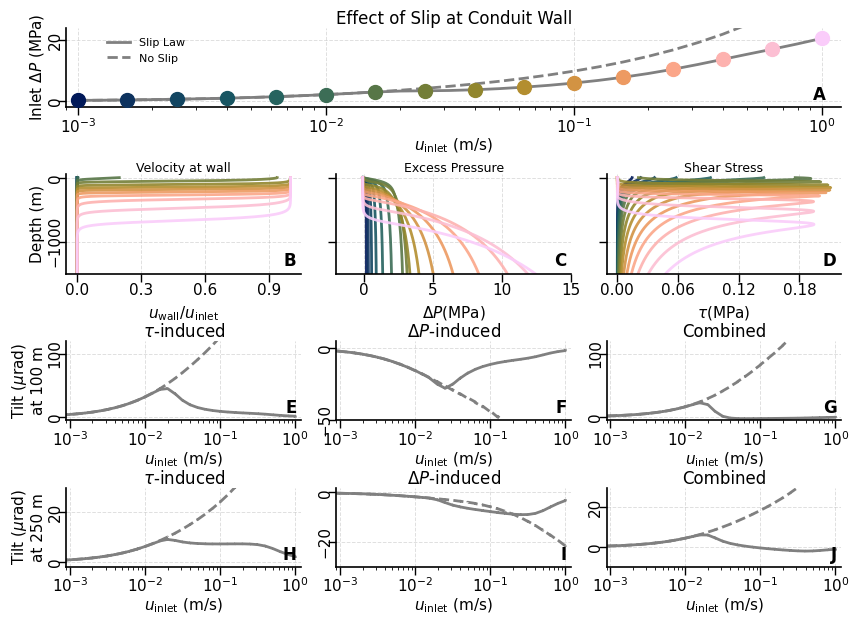

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from matplotlib.ticker import MaxNLocator
from cmcrameri import cm as cmc


# =============================================================================
# GLOBAL PLOT SETTINGS
# =============================================================================

mpl.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 12,
})


# =============================================================================
# DATA AND PLOTTING OPTIONS
# =============================================================================

# Variables shown as depth profiles.
variables = {
    'spf.U': r'$u_{\mathrm{wall}}/u_{\mathrm{inlet}}$',
    'P_excess': r'$\Delta P$(MPa)',
    'spf.mu*spf.sr': r'$\tau$(MPa)',
}

# Slip conditions.
#
# Friction Law:
#   - plotted in all panels
#
# No Slip:
#   - plotted as a dashed reference line in chamber-pressure and tilt panels
#   - NOT plotted in the depth-profile panels
slip_options = [
    'Friction Law',
    'No Slip',
]

# Calculate excess pressure before plotting.
df = calculate_excess_pressure(df)

# Use grey for both slip conditions.
# Linestyle will distinguish the two cases.
slip_to_color = {
    'Friction Law': 'grey',
    'No Slip': 'grey',
}

# Linestyle associated with each slip condition.
slip_to_linestyle = {
    'Friction Law': '-',
    'No Slip': '--',
}


# =============================================================================
# VELOCITIES AND COLOURS
# =============================================================================

# Convert velocities to NumPy array.
velocities = np.asarray(velocities)

# Only consider velocities >= 1e-3 m/s.
velocities = velocities[velocities >= 1e-3]

# Plot every second velocity in the depth-profile panels.
selected_velocities = velocities[::2]
# reverse batlow
vel_colours = [
    cmc.batlow(x)
    for x in np.linspace(0, 1, len(selected_velocities))
]

velocity_to_colour = dict(
    zip(selected_velocities, vel_colours)
)

# =============================================================================
# FIGURE AND GRIDSPEC
#
# Grid layout:
#
#       A A A          row 0: chamber overpressure
#       B C D          row 1: depth profiles
#       E F G          row 2: tilt at 100 m
#       H I J          row 3: tilt at 250 m
#
# =============================================================================

fig = plt.figure(
    figsize=(10, 7)
)

gs = fig.add_gridspec(
    4,
    3,
    height_ratios=[0.8, 1.0, 0.8, 0.8],
    width_ratios=[1, 1, 1],
    hspace=0.8,
    wspace=0.15,
)


# -----------------------------------------------------------------------------
# Row 0: chamber overpressure
# -----------------------------------------------------------------------------

top_ax = fig.add_subplot(
    gs[0, :]
)


# -----------------------------------------------------------------------------
# Row 1: depth profiles
# -----------------------------------------------------------------------------

profile_axes = [
    fig.add_subplot(gs[1, i])
    for i in range(3)
]


# -----------------------------------------------------------------------------
# Row 2: tilt at 100 m
# -----------------------------------------------------------------------------

tilt_100_axes = [
    fig.add_subplot(
        gs[2, i],
        sharex=top_ax,
    )
    for i in range(3)
]


# -----------------------------------------------------------------------------
# Row 3: tilt at 250 m
# -----------------------------------------------------------------------------

tilt_250_axes = [
    fig.add_subplot(
        gs[3, i],
        sharex=top_ax,
    )
    for i in range(3)
]


# =============================================================================
# DEPTH PROFILES
#
# IMPORTANT:
# No Slip is deliberately excluded from these panels.
# =============================================================================

for slip in slip_options:

    # Do not plot No Slip in the depth-profile panels.
    if slip == 'No Slip':
        continue

    # Extract data for this slip condition.
    df_slip = df[
        df['Slip'] == slip
    ]

    # Loop through the selected velocities.
    for velocity_index, velocity in enumerate(selected_velocities):

        data_subset = df_slip[
            df_slip['U_in'] == velocity
        ].sort_values('z')

        if data_subset.empty:
            continue

        depth = data_subset['z']
        colour = vel_colours[velocity_index]
        for j, var in enumerate(variables):

            ax = profile_axes[j]

            # Skip if the variable is absent from the dataframe.
            if var not in data_subset.columns:
                continue

            # ---------------------------------------------------------
            # Pressure and shear stress:
            # convert Pa -> MPa
            # ---------------------------------------------------------
            if var in (
                'P_excess',
                'spf.mu*spf.sr',
            ):

                plot_vals = (
                    data_subset[var]
                    / 1e6
                )

            # ---------------------------------------------------------
            # Wall velocity:
            # normalise by average/inlet velocity
            # ---------------------------------------------------------
            elif var == 'spf.U':

                plot_vals = (
                    data_subset[var]
                    / data_subset['u_av']
                )

            # ---------------------------------------------------------
            # Plot depth profile
            # ---------------------------------------------------------
            ax.plot(
                plot_vals,
                depth,
                color=colour,
                linewidth=2,
                alpha=0.9,
            )


# =============================================================================
# FORMAT DEPTH-PROFILE PANELS
# =============================================================================

for j, (var, xlabel) in enumerate(variables.items()):

    ax = profile_axes[j]

    # Axis label.
    ax.set_xlabel(
        xlabel
    )

    # Depth limits.
    ax.set_ylim(
        -1500,
        50,
    )

    # Limit number of x ticks.
    ax.xaxis.set_major_locator(
        MaxNLocator(
            nbins=4
        )
    )

    # Specific pressure-axis limits.
    if var == 'P_excess':

        ax.set_xlim(
            -2,
            15,
        )

    # Only show depth axis on left-most plot.
    if j == 0:

        ax.set_ylabel(
            'Depth (m)',
            labelpad=2,
        )

    else:

        ax.tick_params(
            axis='y',
            labelleft=False,
        )


# Titles for depth-profile panels.
profile_axes[0].set_title(
    'Velocity at wall',
    fontsize=9,
    pad=2,
)

profile_axes[1].set_title(
    'Excess Pressure',
    fontsize=9,
    pad=2,
)

profile_axes[2].set_title(
    'Shear Stress',
    fontsize=9,
    pad=2,
)


# =============================================================================
# CHAMBER OVERPRESSURE AT THE DEEPEST DEPTH
#
# Friction Law = solid grey
# No Slip      = dashed grey
#
# Coloured velocity markers are only applied to Friction Law.
# =============================================================================

legend_handles = []


for slip in slip_options:

    # Extract relevant data.
    df_slip = df[
        (df['Slip'] == slip)
        &
        (df['U_in'] >= 1e-3)
    ]

    # Skip if no data exist.
    if df_slip.empty:
        continue

    # Get plotting style.
    line_colour = slip_to_color[slip]
    linestyle = slip_to_linestyle[slip]

    # -------------------------------------------------------------------------
    # Find the deepest z for each inlet velocity.
    # -------------------------------------------------------------------------

    deepest_idx = (
        df_slip
        .groupby('U_in')['z']
        .idxmin()
    )

    # Rows corresponding to deepest depth.
    df_deepest = (
        df_slip
        .loc[deepest_idx]
        .sort_values('U_in')
    )

    # Extract velocity.
    velocities_deepest = (
        df_deepest['U_in']
        .to_numpy()
    )

    # Extract P_excess and convert Pa -> MPa.
    p_excess_deepest = (
        df_deepest['P_excess']
        .to_numpy()
        / 1e6
    )

    # -------------------------------------------------------------------------
    # Plot continuous pressure curve.
    # -------------------------------------------------------------------------

    top_ax.semilogx(
        velocities_deepest,
        p_excess_deepest,
        color=line_colour,
        linestyle=linestyle,
        linewidth=2,
        alpha=1,
    )

    # -------------------------------------------------------------------------
    # Add coloured velocity markers only for Friction Law.
    # -------------------------------------------------------------------------

    if slip != 'No Slip':

        for velocity in selected_velocities:

            point = df_deepest[
                df_deepest['U_in'] == velocity
            ]

            if point.empty:
                continue

            p_excess = point['P_excess'].iloc[0] / 1e6

            # Exactly the same lookup used in the depth-profile panels.
            colour = velocity_to_colour[velocity]

            top_ax.semilogx(
                velocity,
                p_excess,
                marker='o',
                markersize=10,
                color=colour,
                linewidth=0,
                zorder=15,
            )

    # -------------------------------------------------------------------------
    # Legend handle.
    # -------------------------------------------------------------------------
    if slip == 'Friction Law':
        label = 'Slip Law'
    else:
        label = slip
    legend_handles.append(
        plt.Line2D(
            [],
            [],
            color=line_colour,
            linestyle=linestyle,
            linewidth=2,
            label=label,
        )
    )


# =============================================================================
# TILT DATA
#
# param_def -> column
#
#   0 -> shear stress only -> tau
#   2 -> pressure only     -> Delta P
#   1 -> combined          -> Combined
#
# Friction Law = solid
# No Slip      = dashed
# =============================================================================

param_to_column = {
    0: 0,
    2: 1,
    1: 2,
}


for slip in slip_options:

    # Get line appearance.
    line_colour = slip_to_color[slip]
    linestyle = slip_to_linestyle[slip]

    for param_def, column in param_to_column.items():

        # ---------------------------------------------------------------------
        # Filter data for slip condition and deformation source.
        # ---------------------------------------------------------------------

        df_param = df_ge[
            (df_ge['Slip'] == slip)
            &
            (df_ge['param_def'] == param_def)
        ]

        if df_param.empty:
            continue


        # =====================================================================
        # TILT AT 100 m
        # =====================================================================

        df_100 = (
            df_param[
                df_param['r'] == 100
            ]
            .sort_values('U_in')
        )

        if not df_100.empty:

            tilt_100_axes[column].semilogx(
                df_100['U_in'],
                df_100['solid.RotrZ'] * 1e6,
                color=line_colour,
                linestyle=linestyle,
                linewidth=2,
                alpha=1,
            )


        # =====================================================================
        # TILT AT 250 m
        # =====================================================================

        df_250 = (
            df_param[
                df_param['r'] == 250
            ]
            .sort_values('U_in')
        )

        if not df_250.empty:

            tilt_250_axes[column].semilogx(
                df_250['U_in'],
                df_250['solid.RotrZ'] * 1e6,
                color=line_colour,
                linestyle=linestyle,
                linewidth=2,
                alpha=1,
            )


# =============================================================================
# AXIS LABELS
# =============================================================================

velocity_label = (
    r'$u_{\mathrm{inlet}}$ (m/s)'
)


# Chamber-pressure x-axis.
top_ax.set_xlabel(
    velocity_label,
    labelpad=1,
)


# Tilt x-axes.
for ax in (
    tilt_100_axes
    +
    tilt_250_axes
):

    ax.set_xlabel(
        velocity_label,
        labelpad=1,
    )


# =============================================================================
# CHAMBER-PRESSURE LABELS
# =============================================================================

top_ax.set_ylabel(
    r'Inlet $\Delta P$ (MPa)',
    labelpad=1,
)

top_ax.set_title(
    'Effect of Slip at Conduit Wall',
    pad=1,
)


# =============================================================================
# TILT LABELS
# =============================================================================

tilt_100_axes[0].set_ylabel(
    r'Tilt ($\mu$rad)' + '\nat 100 m',
    labelpad=1,
)

tilt_250_axes[0].set_ylabel(
    r'Tilt ($\mu$rad)' + '\nat 250 m',
    labelpad=1,
)


# Titles describing deformation source.
tilt_titles = [
    r'$\tau$-induced',
    r'$\Delta P$-induced',
    'Combined',
]


for ax, title in zip(
    tilt_100_axes,
    tilt_titles,
):

    ax.set_title(
        title,
        pad=1,
    )


for ax, title in zip(
    tilt_250_axes,
    tilt_titles,
):

    ax.set_title(
        title,
        pad=1,
    )


# =============================================================================
# AXIS LIMITS
# =============================================================================

# Chamber pressure.
top_ax.set_xlim(
    9e-4,
    1.2,
)

top_ax.set_ylim(
    -2,
    24,
)


# Tilt at 100 m.



# Tilt at 250 m.
for ax in tilt_250_axes:
    if ax == tilt_250_axes[0]:
        ax.set_ylim(
            -2,
            30,
        )
    if ax == tilt_250_axes[1]:
        ax.set_ylim(
            -30,
            2,
        )
    if ax == tilt_250_axes[2]:
        ax.set_ylim(
            -10,
            30,
        )
for ax in tilt_100_axes:
    if ax == tilt_100_axes[0]:
        ax.set_ylim(
            -5,
            120,
        )
    if ax == tilt_100_axes[1]:
        ax.set_ylim(
            -50,
            5,
        )
    if ax == tilt_100_axes[2]:
        ax.set_ylim(
            -5,
            120,
        )

# =============================================================================
# REFERENCE VELOCITY
# =============================================================================

# top_ax.axvline(
#     0.1,
#     color='blue',
#     linestyle='--',
#     linewidth=1,
#     alpha=0.7,
# )


# =============================================================================
# COMMON AXIS STYLING
# =============================================================================

# All axes in their GridSpec reading order.
all_axes = (
    [top_ax]
    +
    profile_axes
    +
    tilt_100_axes
    +
    tilt_250_axes
)


for ax in all_axes:

    # Tick style.
    ax.tick_params(
        axis='both',
        which='major',
        direction='out',
        length=6,
        width=1,
        pad=1,
    )

    # Grid.
    ax.grid(
        True,
        alpha=0.4,
        linestyle='--',
        linewidth=0.7,
    )

    # Remove top/right spines.
    ax.spines['top'].set_visible(
        False
    )

    ax.spines['right'].set_visible(
        False
    )

    # Set remaining spine widths.
    ax.spines['left'].set_linewidth(
        1.2
    )

    ax.spines['bottom'].set_linewidth(
        1.2
    )


# =============================================================================
# LEGEND
#
# Solid grey  = Friction Law
# Dashed grey = No Slip
# =============================================================================

top_ax.legend(
    handles=legend_handles,
    fontsize=8,
    loc='upper left',
    bbox_to_anchor=(0.04, 1),
    frameon=False,
)


# =============================================================================
# PANEL LETTERS
#
# GridSpec reading order:
#
#       A
#     B C D
#     E F G
#     H I J
#
# All panel letters are placed in the bottom-right corner.
# =============================================================================

panel_axes = (
    [top_ax]
    +
    profile_axes
    +
    tilt_100_axes
    +
    tilt_250_axes
)


for i, ax in enumerate(panel_axes):

    panel_letter = chr(
        ord('A') + i
    )

    ax.text(
        0.98,
        0.04,
        panel_letter,
        transform=ax.transAxes,
        fontsize=12,
        fontweight='bold',
        ha='right',
        va='bottom',
        bbox=dict(
            facecolor='none',
            edgecolor='none',
            alpha=0.7,
        ),
        zorder=10,
    )
    
    ax.tick_params(axis='y', labelrotation=90,pad=2)
    for label in ax.get_yticklabels():
        label.set_horizontalalignment('center')
        label.set_verticalalignment('center')

# =============================================================================
# FINAL LAYOUT
# =============================================================================

fig.tight_layout(
    rect=[
        0,
        0,
        0.85,
        1,
    ]
)


# =============================================================================
# OPTIONAL: SAVE FIGURE
# =============================================================================
fig.savefig('../../output_plots/slip_models_figure.pdf', dpi=300)
plt.show()